## 1. Configuration

In [1]:
import json, itertools, gc, time, csv, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

PATH      = "/kaggle/input/competitions/otto-recommender-system/train.jsonl"
TEST_PATH = "/kaggle/input/competitions/otto-recommender-system/test.jsonl"

N_VAL, N_RANK, N_COV = 20_000, 150_000, 3_000_000
VAL_START, RANK_START = 0, N_VAL
COV_START = N_VAL + N_RANK
CHUNK = 50_000

TYPES   = ["clicks", "carts", "orders"]
TYPE_ID = {"clicks": 0, "carts": 1, "orders": 2}
TYPE_W_NP = np.array([1.0, 3.0, 6.0], dtype=np.float32)  # poids des voisins (co-visitation)
W_OWN = (1.0, 4.0, 4.0)          # poids des événements de la session
WINDOW_SEC, MAX_EV = 3600, 30    # fenêtre temporelle, événements par session
K_NB, LAST_N, N_NB = 20, 5, 20   # voisins gardés / derniers produits utilisés / candidats voisins
MAX_HIST, MAX_OWN = 100, 30
MAX_AID = 2_000_000
RUN_SUBMISSION = False           # True pour générer submission.csv (long)

## 2. Lecture des données

In [2]:
def read_sessions(path, start, stop):
    with open(path) as f:
        return [json.loads(l) for l in itertools.islice(f, start, stop)]

def lines_to_df(lines):
    S, A, T, Y = [], [], [], []
    for line in lines:
        s = json.loads(line)
        sid = s["session"]
        for e in s["events"]:
            S.append(sid); A.append(e["aid"]); T.append(e["ts"] // 1000); Y.append(TYPE_ID[e["type"]])
    return pd.DataFrame({"session": np.array(S, np.int32), "aid": np.array(A, np.int32),
                         "ts": np.array(T, np.int32), "type": np.array(Y, np.int8)})

def stream_chunks(path, start, stop, chunk):
    """Lit le fichier une seule fois, par morceaux de `chunk` sessions."""
    with open(path) as f:
        for _ in itertools.islice(f, start):
            pass
        pos = start
        while pos < stop:
            lines = list(itertools.islice(f, min(chunk, stop - pos)))
            if not lines:
                break
            yield lines_to_df(lines)
            pos += len(lines)

val_sessions = read_sessions(PATH, VAL_START, VAL_START + N_VAL)
print("Sessions de validation :", len(val_sessions))

Sessions de validation : 20000


## 3. Exploration rapide (sessions de validation)

Longueur moyenne : 56.4 | max : 495
Types d'événements : {'clicks': 1027514, 'carts': 79598, 'orders': 20535}


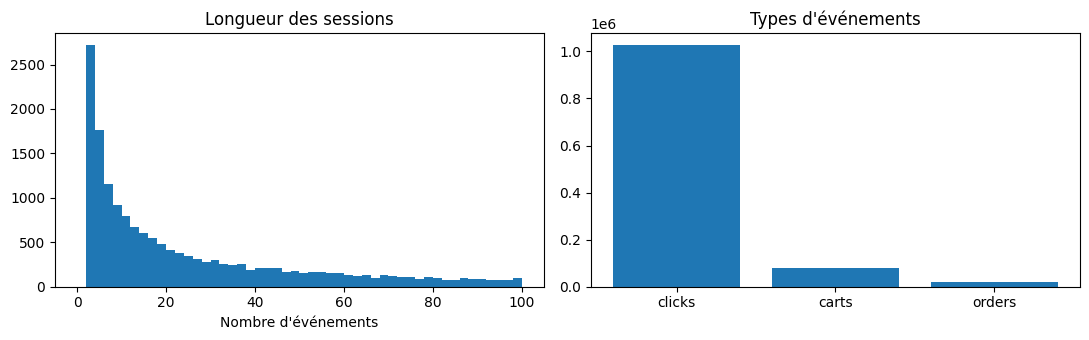

In [3]:
lengths = [len(s["events"]) for s in val_sessions]
types = Counter(e["type"] for s in val_sessions for e in s["events"])
print("Longueur moyenne :", round(sum(lengths) / len(lengths), 1), "| max :", max(lengths))
print("Types d'événements :", dict(types))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(lengths, bins=50, range=(0, 100)); ax[0].set_title("Longueur des sessions")
ax[0].set_xlabel("Nombre d'événements")
ax[1].bar(types.keys(), types.values()); ax[1].set_title("Types d'événements")
plt.tight_layout(); plt.show()

## 4. Matrice de co-visitation (3 M de sessions)

In [4]:
def covisit_chunk(df):
    df = df.sort_values(["session", "ts"])
    df["n"] = df.groupby("session").cumcount(ascending=False)
    df = df[df.n < MAX_EV][["session", "aid", "ts", "type"]]
    m = df.merge(df, on="session", suffixes=("_x", "_y"))
    m = m[(m.aid_x != m.aid_y) & ((m.ts_x - m.ts_y).abs() < WINDOW_SEC)]
    m["w"] = TYPE_W_NP[m["type_y"].values]
    return m.groupby(["aid_x", "aid_y"], as_index=False)["w"].sum()

def merge_parts(parts):
    return pd.concat(parts).groupby(["aid_x", "aid_y"], as_index=False)["w"].sum()

def prune(df, k=50):
    df = df.sort_values(["aid_x", "w"], ascending=[True, False])
    return df.groupby("aid_x").head(k)

class Cov:
    """Voisins de chaque produit : tableaux triés par poids décroissant."""
    def __init__(self, df, k=K_NB):
        df = df.sort_values(["aid_x", "w"], ascending=[True, False]).groupby("aid_x").head(k)
        self.ay = df.aid_y.values
        self.w = df.w.values
        ax = df.aid_x.values
        u, start = np.unique(ax, return_index=True)
        end = np.append(start[1:], len(ax))
        self.idx = dict(zip(u.tolist(), zip(start.tolist(), end.tolist())))
    def get(self, a):
        se = self.idx.get(a)
        if se is None:
            return None
        return self.ay[se[0]:se[1]], self.w[se[0]:se[1]]

t0 = time.time()
pop = np.zeros(MAX_AID, dtype=np.int64)
parts = []
for i, df in enumerate(stream_chunks(PATH, COV_START, COV_START + N_COV, CHUNK)):
    pop += np.bincount(df.aid.values, minlength=MAX_AID)
    parts.append(covisit_chunk(df))
    if len(parts) >= 4:
        parts = [prune(merge_parts(parts))]
    gc.collect()
    if (i + 1) % 10 == 0:
        print(f"{(i + 1) * CHUNK:>9,} sessions | {(time.time() - t0) / 60:.1f} min")
cov = Cov(prune(merge_parts(parts)))
del parts; gc.collect()
top20 = np.argsort(-pop)[:20].tolist()
print("Co-visitation prête :", len(cov.idx), "produits |", round((time.time() - t0) / 60, 1), "min")

  500,000 sessions | 2.1 min
1,000,000 sessions | 4.4 min
1,500,000 sessions | 7.1 min
2,000,000 sessions | 10.9 min
2,500,000 sessions | 13.8 min
3,000,000 sessions | 16.8 min
Co-visitation prête : 1543711 produits | 17.7 min


## 5. Candidats et features

In [5]:
FEATS = ["n_click", "n_cart", "n_order", "last_r", "first_r", "own_score", "mins_last",
         "nb_score", "nb_cnt", "nb_rank", "log_pop", "is_own", "n_events", "n_unique",
         "last_type", "sess_min"]
F = {n: i for i, n in enumerate(FEATS)}

def split_session(events):
    """Coupure pseudo-aléatoire, identique pour tous les modèles."""
    if len(events) < 2:
        return events, []
    rnd = random.Random(len(events) * 7919 + events[0]["ts"] % 1000)
    cut = rnd.randint(1, len(events) - 1)
    return events[:cut], events[cut:]

def session_features(history):
    history = history[-MAX_HIST:]
    t_end = history[-1]["ts"] / 1000
    own = {}
    for r, e in enumerate(reversed(history)):
        a, ti = e["aid"], TYPE_ID[e["type"]]
        d = own.get(a)
        if d is None:
            d = own[a] = [0, 0, 0, r, r, 0.0, (t_end - e["ts"] / 1000) / 60]
        d[ti] += 1
        d[4] = r
        d[5] += W_OWN[ti] / (1 + r)
    nb_score, nb_cnt = {}, {}
    for r, e in enumerate(reversed(history[-LAST_N:])):
        nb = cov.get(e["aid"])
        if nb is None:
            continue
        ids, ws = nb
        f = 1.0 / (1 + r)
        for a, w in zip(ids.tolist(), (ws / ws[0]).tolist()):
            nb_score[a] = nb_score.get(a, 0.0) + w * f
            nb_cnt[a] = nb_cnt.get(a, 0) + 1
    nb_sorted = sorted(nb_score, key=nb_score.get, reverse=True)
    nb_rank = {a: i for i, a in enumerate(nb_sorted)}
    own_top = sorted(own, key=lambda a: own[a][5], reverse=True)[:MAX_OWN]
    own_set = set(own_top)
    cands = own_top + [a for a in nb_sorted if a not in own_set][:N_NB]

    n, n_unique = len(history), len(own)
    last_type = TYPE_ID[history[-1]["type"]]
    sess_min = (t_end - history[0]["ts"] / 1000) / 60
    X = np.empty((len(cands), len(FEATS)), dtype=np.float32)
    for i, a in enumerate(cands):
        d = own.get(a)
        if d:
            c, ca, o, last_r, first_r, sc, ml = d
        else:
            c = ca = o = 0; last_r = first_r = 999; sc = 0.0; ml = 9999
        X[i] = (c, ca, o, last_r, first_r, sc, ml,
                nb_score.get(a, 0.0), nb_cnt.get(a, 0), nb_rank.get(a, 999),
                np.log1p(pop[a]) if a < MAX_AID else 0.0, d is not None,
                n, n_unique, last_type, sess_min)
    return cands, X

## 6. Prédiction, métrique et baselines

In [6]:
def predict_batch(histories, scorers):
    cand, feats = [], []
    for h in histories:
        a, X = session_features(h)
        cand.append(a); feats.append(X)
    Xall = np.vstack(feats)
    bounds = np.cumsum([0] + [len(a) for a in cand])
    out = [{} for _ in histories]
    for t in TYPES:
        p = scorers[t](Xall)
        for i, a in enumerate(cand):
            s = p[bounds[i]:bounds[i + 1]]
            lst = [a[j] for j in np.argsort(-s)[:20]]
            if len(lst) < 20:
                lst += [x for x in top20 if x not in lst][:20 - len(lst)]
            out[i][t] = lst
    return out

def recall_score(preds, futures):
    """Somme globale des hits / somme de min(20, nb de vrais produits), comme Kaggle."""
    hits, den = dict.fromkeys(TYPES, 0), dict.fromkeys(TYPES, 0)
    for p, fut in zip(preds, futures):
        for t in TYPES:
            truth = [e["aid"] for e in fut if e["type"] == t]
            if t == "clicks":
                truth = truth[:1]
            truth = set(truth)
            hits[t] += len(set(p[t][:20]) & truth)
            den[t] += min(20, len(truth))
    R = {t: hits[t] / den[t] for t in TYPES if den[t]}
    return R, 0.1 * R["clicks"] + 0.3 * R["carts"] + 0.6 * R["orders"]

results = {}
def report(name, preds, futures):
    R, s = recall_score(preds, futures)
    results[name] = {**{t: round(v, 4) for t, v in R.items()}, "score": round(s, 4)}
    print(f"{name:<30}", results[name])

pairs = [split_session(s["events"]) for s in val_sessions]
pairs = [(h, f) for h, f in pairs if f]
val_hist, val_fut = [h for h, _ in pairs], [f for _, f in pairs]

report("Popularité", [{t: top20 for t in TYPES} for _ in val_hist], val_fut)
last_scorer = lambda X: X[:, F["is_own"]] * (1e6 - X[:, F["last_r"]])
report("Derniers vus", predict_batch(val_hist, {t: last_scorer for t in TYPES}), val_fut)
heur_scorer = lambda X: X[:, F["own_score"]] * 1000 + X[:, F["nb_score"]]
report("Co-visitation (heuristique)", predict_batch(val_hist, {t: heur_scorer for t in TYPES}), val_fut)

Popularité                     {'clicks': 0.0082, 'carts': 0.0085, 'orders': 0.0072, 'score': 0.0077}
Derniers vus                   {'clicks': 0.398, 'carts': 0.1481, 'orders': 0.2867, 'score': 0.2562}
Co-visitation (heuristique)    {'clicks': 0.3993, 'carts': 0.1544, 'orders': 0.3107, 'score': 0.2727}


## 7. Re-ranking LightGBM

In [7]:
def make_training(sessions):
    Xs, ys = [], {t: [] for t in TYPES}
    for s in sessions:
        hist, fut = split_session(s["events"])
        if not fut:
            continue
        a, X = session_features(hist)
        Xs.append(X)
        for t in TYPES:
            truth = [e["aid"] for e in fut if e["type"] == t]
            truth = set(truth[:1]) if t == "clicks" else set(truth)
            ys[t].append(np.array([x in truth for x in a], dtype=np.int8))
    return np.vstack(Xs), {t: np.concatenate(v) for t, v in ys.items()}

t0 = time.time()
rank_sessions = read_sessions(PATH, RANK_START, RANK_START + N_RANK)
X_tr, y_tr = make_training(rank_sessions)
del rank_sessions; gc.collect()
print("Entraînement :", X_tr.shape, "| positifs :", {t: int(y.sum()) for t, y in y_tr.items()},
      "|", round((time.time() - t0) / 60, 1), "min")

models = {}
for t in TYPES:
    models[t] = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=63,
                                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                   random_state=0, verbose=-1)
    models[t].fit(X_tr, y_tr[t])
lgb_scorers = {t: (lambda X, m=models[t]: m.predict_proba(X)[:, 1]) for t in TYPES}

report("Co-visitation + LightGBM", predict_batch(val_hist, lgb_scorers), val_fut)

imp = pd.Series(models["orders"].feature_importances_, index=FEATS).sort_values(ascending=False)
print("\nImportance des features (orders) :\n", imp.head(8))

Entraînement : (4504769, 16) | positifs : {'clicks': 65464, 'carts': 40312, 'orders': 27635} | 1.4 min


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Co-visitation + LightGBM       {'clicks': 0.4129, 'carts': 0.1573, 'orders': 0.3171, 'score': 0.2787}

Importance des features (orders) :
 log_pop      4025
nb_score     3506
sess_min     2526
nb_rank      2477
n_events     1264
n_unique     1223
mins_last     757
own_score     634
dtype: int32


## 8. Tableau récapitulatif et diagnostic des candidats


In [8]:
print(pd.DataFrame(results).T)

def candidate_recall(hists, futs):
    hit = dict.fromkeys(TYPES, 0); den = dict.fromkeys(TYPES, 0)
    for h, fut in zip(hists, futs):
        cands, _ = session_features(h)
        cs = set(cands)
        for t in TYPES:
            truth = [e["aid"] for e in fut if e["type"] == t]
            truth = set(truth[:1]) if t == "clicks" else set(truth)
            hit[t] += len(cs & truth); den[t] += min(20, len(truth))
    return {t: round(hit[t] / den[t], 4) for t in TYPES if den[t]}

print("Recall maximal des candidats :", candidate_recall(val_hist, val_fut))

                             clicks   carts  orders   score
Popularité                   0.0082  0.0085  0.0072  0.0077
Derniers vus                 0.3980  0.1481  0.2867  0.2562
Co-visitation (heuristique)  0.3993  0.1544  0.3107  0.2727
Co-visitation + LightGBM     0.4129  0.1573  0.3171  0.2787
Recall maximal des candidats : {'clicks': 0.4414, 'carts': 0.1817, 'orders': 0.3386}


## 9. Soumission (optionnelle)


In [9]:
if RUN_SUBMISSION:
    t0, BATCH, n_done = time.time(), 20_000, 0
    with open(TEST_PATH) as f, open("/kaggle/working/submission.csv", "w", newline="") as out:
        w = csv.writer(out)
        w.writerow(["session_type", "labels"])
        while True:
            lines = list(itertools.islice(f, BATCH))
            if not lines:
                break
            sess = [json.loads(l) for l in lines]
            preds = predict_batch([s["events"] for s in sess], lgb_scorers)
            for s, p in zip(sess, preds):
                for t in TYPES:
                    w.writerow([f"{s['session']}_{t}", " ".join(map(str, p[t]))])
            n_done += len(sess)
            print(f"{n_done:,} sessions écrites | {(time.time() - t0) / 60:.1f} min")
    print("submission.csv écrit")